In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, Button, HBox, VBox, Output, HTML,interactive_output
from IPython.display import display, clear_output


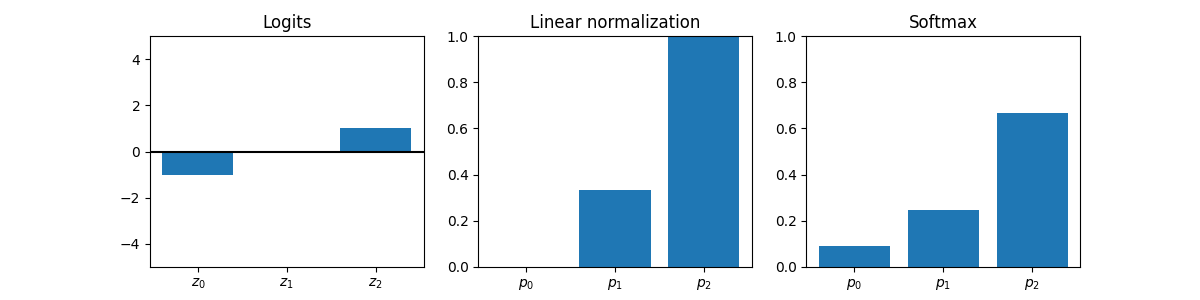

In [2]:
%matplotlib widget

z0 = widgets.FloatSlider(
    value=-1, min=-5, max=5, step=.05,
    description=r'$z_0$'
)
z1 = widgets.FloatSlider(
    value=0, min=-5, max=5, step=.05,
    description=r'$z_1$'
)
z2 = widgets.FloatSlider(
    value=1, min=-5, max=5, step=.05,
    description=r'$z_2$'
)

# Create the figure ONCE
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 3))

# Bars we will keep updating
bars1 = ax1.bar([0, 1, 2], [0, 0, 0])
bars2 = ax2.bar([0, 1, 2], [0, 0, 0])
bars3 = ax3.bar([0, 1, 2], [0, 0, 0])

ax1.set_title("Logits")
ax1.axhline(0,color="black")
ax1.set_xticks(np.arange(3), [r"$z_0$", r"$z_1$", r"$z_2$"])
ax1.set_ylim(-5, 5)

ax2.set_title("Linear normalization")
ax2.set_xticks(np.arange(3), [r"$p_0$", r"$p_1$", r"$p_2$"])
ax2.set_ylim(0, 1)

ax3.set_title("Softmax")
ax3.set_xticks(np.arange(3), [r"$p_0$", r"$p_1$", r"$p_2$"])
ax3.set_ylim(0, 1)


def update(change=None):
    # Logits
    theta = np.array([z0.value, z1.value, z2.value])
    # Linear normalization
    pos_theta = theta +10e-5#- theta.min() + 10e-5
    lin_theta = pos_theta / pos_theta.sum()
    # Softmax
    e_theta = np.exp(theta - theta.max())
    soft_theta = e_theta / e_theta.sum()

    # Update existing bars rather than recreating the figure
    for bar, value in zip(bars1, theta):
        bar.set_height(value)

    for bar, value in zip(bars2, lin_theta):
        bar.set_height(value)

    for bar, value in zip(bars3, soft_theta):
        bar.set_height(value)

    fig.canvas.draw_idle()


for slider in (z0, z1, z2):
    slider.observe(update, names="value")

update()

display(
    widgets.VBox([
        widgets.VBox([z0, z1, z2]),
        fig.canvas
    ])
)

In [6]:
z = np.array([z0.value,z1.value,z2.value])
e_z = np.exp(z - z.max())
soft_z = e_z / e_z.sum()

In [16]:
np.arange(3)+0.5

array([0.5, 1.5, 2.5])

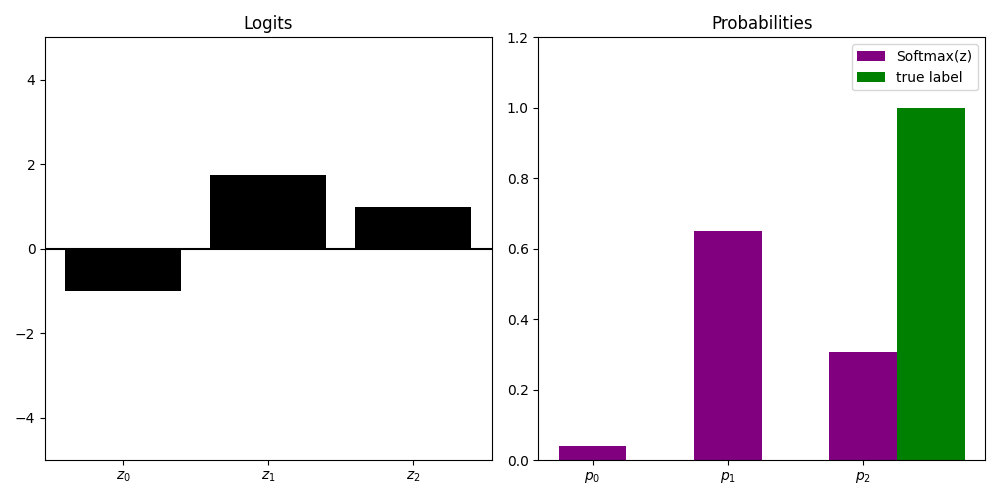

In [27]:
fig, (ax1,ax2) = plt.subplots(1,2, figsize=(10,5))

ax1.set_title("Logits")
ax1.bar(np.arange(3), z, color="black")
ax1.axhline(0,color="black")
ax1.set_xticks(np.arange(3), [r"$z_0$", r"$z_1$", r"$z_2$"])
ax1.set_ylim(-5, 5)

ax2.set_title("Probabilities")
ax2.bar(np.arange(3), soft_z, width=0.5,label="Softmax(z)", color="purple")
ax2.bar(np.arange(3)+0.5, [0,0,1], width=0.5, label="true label", color="green")
ax2.set_xticks(np.arange(3), [r"$p_0$", r"$p_1$", r"$p_2$"])
ax2.set_ylim(0, 1.2)
ax2.legend()

plt.tight_layout()
plt.savefig("plots/distance_softmax_true.pdf")
plt.show()